<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Matplotlib para Engenharia — Visualização e Interpretação de Dados.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Em Engenharia, um gráfico não é apenas uma ilustração: ele permite investigar tendências, comparar resultados com modelos, reconhecer anomalias e comunicar decisões. Neste notebook aprenderemos a construir gráficos com **Matplotlib**, relacionando cada representação aos fenômenos físicos e às unidades de medida.

**Metodologia:** problema de Engenharia → equação ou interpretação física → verificação manual → código Python → leitura crítica do gráfico. Os dados são didáticos; não representam especificações industriais ou ensaios certificados.

**Sumário**

1. [Por que representar dados graficamente?](#secao-1)
2. [Preparação do Matplotlib](#secao-2)
3. [Primeiro gráfico: temperatura de um tanque](#secao-3)
4. [Elementos de um gráfico técnico](#secao-4)
5. [Comparando experimentos](#secao-5)
6. [Instrumentação: calibração de transmissor](#secao-6)
7. [Controle de Qualidade: dispersão de medições](#secao-7)
8. [Controle de Processos: referência, resposta e erro](#secao-8)
9. [Mecânica dos Fluidos: Reynolds e velocidade](#secao-9)
10. [Transferência de Calor: resfriamento](#secao-10)
11. [Processos Químicos: conversão em função do tempo](#secao-11)
12. [Ciências dos Materiais: curva tensão–deformação](#secao-12)
13. [Gráficos de dispersão e ajuste linear](#secao-13)
14. [Múltiplos gráficos e organização visual](#secao-14)
15. [Salvando figuras para relatórios](#secao-15)
16. [Boas práticas e erros de interpretação](#secao-16)
17. [Exercícios de consolidação](#secao-17)
18. [Síntese do notebook](#secao-18)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. Por que representar dados graficamente?</div>

Uma tabela mostra valores exatos, enquanto um gráfico evidencia relações entre grandezas. Antes de escolher um tipo de gráfico, pergunte: qual variável é independente? Qual é a resposta medida? Qual unidade corresponde a cada eixo? Há dados experimentais ou resultados de um modelo?

Usaremos gráficos de linhas para evolução temporal, dispersão para pares experimentais e barras para comparação de categorias. Evitaremos unir pontos com linhas quando não existir uma sequência física que justifique essa ligação.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Preparação do Matplotlib</div>

O Matplotlib é uma biblioteca de visualização. Se necessário, instale-a no ambiente selecionado do VS Code com `python -m pip install matplotlib numpy`. Usaremos a interface `pyplot` e o NumPy, estudado no Notebook 12. O comando `plt.show()` apresenta a figura; `plt.close()` libera seus recursos após a apresentação.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Matplotlib disponível para os exemplos.")

NumPy: 2.3.5
Matplotlib disponível para os exemplos.


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Primeiro gráfico: temperatura de um tanque</div>

**Problema — Modelagem de um tanque.** Um tanque inicialmente contém 50 L, recebe 5 L/min e descarrega 4 L/min. Pelo balanço de volume, $dV/dt=Q_{in}-Q_{out}=1$ L/min. Para vazões constantes, $V(t)=50+t$, com $t$ em minutos e $V$ em litros.

**Cálculo manual:** em $t=10$ min, $V(10)=50+10=60$ L. O gráfico deve ser uma reta crescente, pois a taxa de acúmulo é constante.

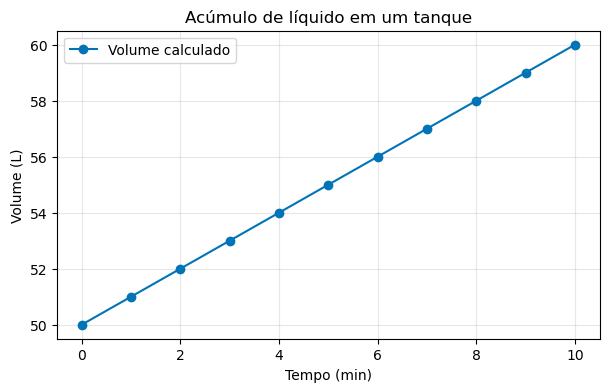

In [2]:
tempo_min = np.arange(0, 11, 1)
volume_L = 50 + tempo_min

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo_min, volume_L, marker="o", color="#0074B7", label="Volume calculado")
ax.set(xlabel="Tempo (min)", ylabel="Volume (L)", title="Acúmulo de líquido em um tanque")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Interpretação:** a reta confirma um acréscimo de 1 L a cada minuto. O gráfico não verifica, por si só, se a capacidade física do tanque é suficiente; esse limite precisaria ser informado.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Elementos de um gráfico técnico</div>

Um gráfico técnico deve apresentar identificação dos eixos, unidades, título informativo e escala legível. Uma legenda é útil quando existem duas ou mais curvas. A grade pode facilitar a leitura, desde que não esconda os dados.

`fig, ax = plt.subplots()` cria uma figura e seus eixos. Preferiremos `ax.plot()`, `ax.set_xlabel()` e `ax.set_ylabel()` porque essa organização facilita acrescentar outras curvas sem confundir a configuração da figura.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Comparando experimentos</div>

**Problema — Comparação de dois ensaios térmicos.** Dois equipamentos apresentam históricos diferentes de temperatura. Para comparar suas respostas, representaremos ambas as curvas no mesmo sistema de eixos. Os dados são hipotéticos e foram escolhidos para exercitar a interpretação.

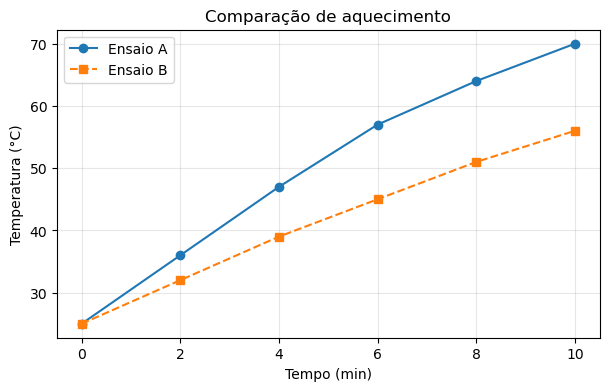

In [3]:
tempo = np.array([0, 2, 4, 6, 8, 10])
ensaio_A = np.array([25, 36, 47, 57, 64, 70])
ensaio_B = np.array([25, 32, 39, 45, 51, 56])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo, ensaio_A, "o-", label="Ensaio A")
ax.plot(tempo, ensaio_B, "s--", label="Ensaio B")
ax.set(xlabel="Tempo (min)", ylabel="Temperatura (°C)", title="Comparação de aquecimento")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Interpretação:** ambos começam a 25 °C, mas o ensaio A apresenta maior temperatura nos instantes posteriores. A comparação não demonstra, isoladamente, qual equipamento é mais eficiente energeticamente.

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Instrumentação: calibração de transmissor</div>

**Problema — Instrumentação e Controle de Qualidade.** Um transmissor ideal converte pressão de 0 a 10 bar em corrente de 4 a 20 mA. A relação é $I=4+16P/10$, com corrente em mA e pressão em bar.

**Cálculo manual:** para $P=5$ bar, $I=4+16\times5/10=12$ mA. Vamos comparar leituras hipotéticas com a reta ideal. O desvio em mA é a diferença entre a leitura e a corrente prevista; não constitui, por si só, uma calibração metrológica.

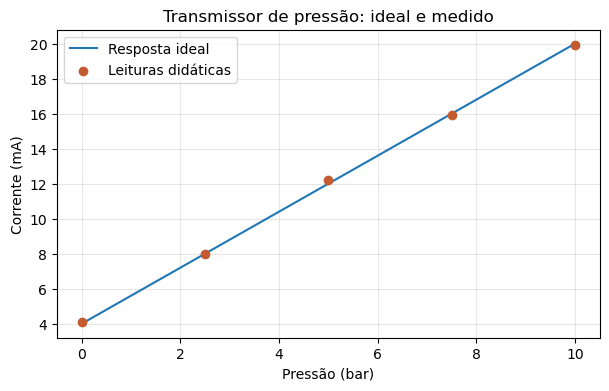

Desvios (mA): [ 0.1  0.   0.2 -0.1 -0.1]


In [4]:
pressao_bar = np.array([0, 2.5, 5, 7.5, 10])
corrente_ideal = 4 + 16 * pressao_bar / 10
corrente_medida = np.array([4.1, 8.0, 12.2, 15.9, 19.9])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pressao_bar, corrente_ideal, label="Resposta ideal")
ax.scatter(pressao_bar, corrente_medida, color="#c45a30", label="Leituras didáticas", zorder=3)
ax.set(xlabel="Pressão (bar)", ylabel="Corrente (mA)", title="Transmissor de pressão: ideal e medido")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
print("Desvios (mA):", np.round(corrente_medida - corrente_ideal, 2))

**Interpretação:** os pontos medidos ficam próximos da reta ideal. A avaliação metrológica real também exige rastreabilidade, incerteza e critérios de aceitação previamente definidos.

<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Controle de Qualidade: dispersão de medições</div>

**Problema — Controle de Qualidade.** Um laboratório mede a concentração de seis amostras. Para fins didáticos, adotaremos uma faixa de referência hipotética de 9,5 a 10,5 g/L. Um gráfico de pontos permite identificar visualmente as amostras que ficam fora dessa faixa.

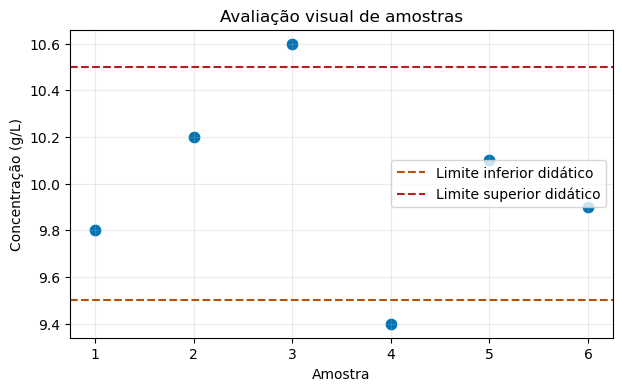

Amostras fora da faixa: [3 4]


In [5]:
amostras = np.arange(1, 7)
concentracao = np.array([9.8, 10.2, 10.6, 9.4, 10.1, 9.9])

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(amostras, concentracao, color="#0074B7", s=55)
ax.axhline(9.5, color="#b45309", linestyle="--", label="Limite inferior didático")
ax.axhline(10.5, color="#b91c1c", linestyle="--", label="Limite superior didático")
ax.set(xlabel="Amostra", ylabel="Concentração (g/L)", title="Avaliação visual de amostras")
ax.set_xticks(amostras)
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()
print("Amostras fora da faixa:", amostras[(concentracao < 9.5) | (concentracao > 10.5)])

**Interpretação:** as amostras 3 e 4 estão fora da faixa didática. O gráfico facilita identificar quais medições precisam ser investigadas, mas não substitui o procedimento de controle de qualidade.

<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Controle de Processos: referência, resposta e erro</div>

**Problema — Controle de Processos Aplicado.** Para uma referência $T_{SP}=80$ °C, o erro é $e(t)=T_{SP}-T(t)$. Considere uma sequência de medições após uma mudança operacional.

**Cálculo manual:** se $T(0)=70$ °C, então $e(0)=80-70=10$ °C. Representaremos referência e temperatura na mesma figura e o erro em outra figura, pois são leituras com interpretações diferentes.

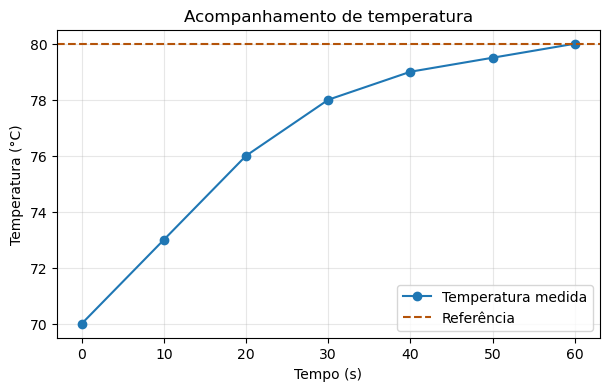

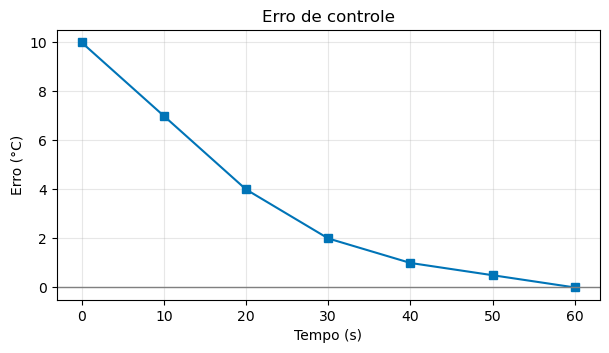

In [6]:
tempo_s = np.array([0, 10, 20, 30, 40, 50, 60])
temperatura = np.array([70, 73, 76, 78, 79, 79.5, 80])
referencia = 80.0
erro = referencia - temperatura

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo_s, temperatura, "o-", label="Temperatura medida")
ax.axhline(referencia, linestyle="--", color="#b45309", label="Referência")
ax.set(xlabel="Tempo (s)", ylabel="Temperatura (°C)", title="Acompanhamento de temperatura")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tempo_s, erro, "s-", color="#0074B7")
ax.axhline(0, color="gray", linewidth=1)
ax.set(xlabel="Tempo (s)", ylabel="Erro (°C)", title="Erro de controle")
ax.grid(True, alpha=0.3)
plt.show()

**Interpretação:** o erro diminui até zero nos dados apresentados. A sequência isolada não é suficiente para demonstrar estabilidade ou robustez de um controlador PID.

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Mecânica dos Fluidos: Reynolds e velocidade</div>

**Problema — Mecânica dos Fluidos.** Em um tubo circular, $Re=\rho vD/\mu$. Para água em condições didáticas, considere $\rho=1000$ kg/m³, $D=0{,}02$ m e $\mu=0{,}001$ Pa·s.

**Cálculo manual:** em $v=0{,}10$ m/s, $Re=1000\times0{,}10\times0{,}02/0{,}001=2000$. Como as demais propriedades permanecem constantes, o gráfico de $Re$ em função de $v$ deve ser linear.

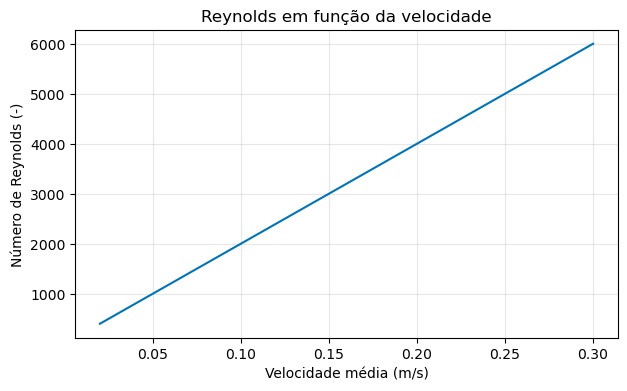

In [7]:
velocidades = np.linspace(0.02, 0.30, 30)
rho, D, mu = 1000.0, 0.02, 0.001
reynolds = rho * velocidades * D / mu

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(velocidades, reynolds, color="#0074B7")
ax.set(xlabel="Velocidade média (m/s)", ylabel="Número de Reynolds (-)", title="Reynolds em função da velocidade")
ax.grid(True, alpha=0.3)
plt.show()

**Interpretação:** o número de Reynolds cresce proporcionalmente à velocidade. A identificação do regime de escoamento exige considerar a geometria e as condições do problema.

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Transferência de Calor: resfriamento</div>

**Problema — Transferência de Calor.** Um corpo resfria em um ambiente com temperatura constante $T_\infty$. Sob a hipótese de capacidade térmica concentrada, $T(t)=T_\infty+(T_0-T_\infty)e^{-kt}$.

Adotando $T_0=90$ °C, $T_\infty=25$ °C e $k=0{,}05$ min$^{-1}$, em $t=0$ a expressão fornece $T(0)=25+65=90$ °C. A curva deve se aproximar de 25 °C sem ultrapassar esse valor no modelo.

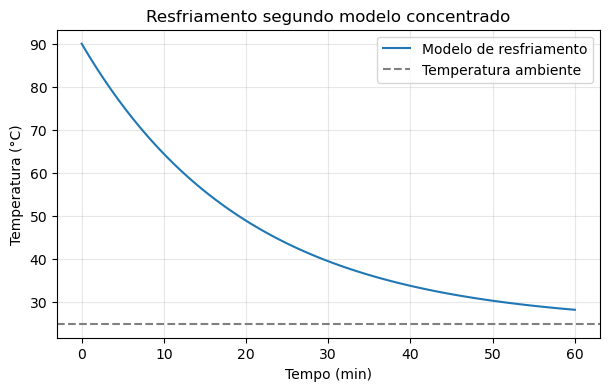

In [8]:
tempo_min = np.linspace(0, 60, 121)
T_ambiente, T_inicial, k = 25.0, 90.0, 0.05
T_modelo = T_ambiente + (T_inicial - T_ambiente) * np.exp(-k * tempo_min)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo_min, T_modelo, label="Modelo de resfriamento")
ax.axhline(T_ambiente, linestyle="--", color="gray", label="Temperatura ambiente")
ax.set(xlabel="Tempo (min)", ylabel="Temperatura (°C)", title="Resfriamento segundo modelo concentrado")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Interpretação:** o resfriamento é mais rápido no início, quando a diferença de temperatura é maior. O modelo pressupõe temperatura aproximadamente uniforme no corpo; sua aplicabilidade depende das características físicas do sistema.

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Processos Químicos: conversão em função do tempo</div>

**Problema — Processos Químicos de Fabricação.** Considere um modelo didático de conversão crescente $X(t)=1-e^{-kt}$, com $k=0{,}12$ min$^{-1}$. Esse modelo pode representar uma cinética aparente simplificada, mas não deve ser aplicado a um processo real sem validação.

**Cálculo manual:** em $t=0$, $X(0)=1-1=0$. A conversão é adimensional e tende a 1 quando o tempo cresce.

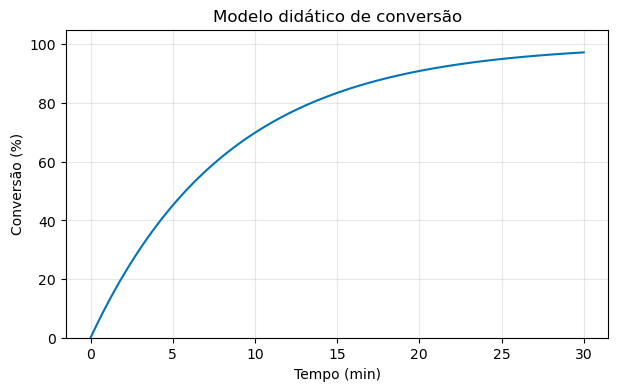

In [9]:
tempo_reacao = np.linspace(0, 30, 121)
k_reacao = 0.12
conversao = 1 - np.exp(-k_reacao * tempo_reacao)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo_reacao, 100 * conversao, color="#0074B7")
ax.set(xlabel="Tempo (min)", ylabel="Conversão (%)", title="Modelo didático de conversão")
ax.set_ylim(0, 105)
ax.grid(True, alpha=0.3)
plt.show()

**Interpretação:** a conversão cresce e se aproxima de 100%, sem ultrapassar esse limite no modelo. Um processo real pode apresentar limitações de equilíbrio, transferência de massa ou reações paralelas.

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Ciências dos Materiais: curva tensão–deformação</div>

**Problema — Ciências dos Materiais.** Em um ensaio de tração, o trecho elástico inicial pode ser aproximado por $\sigma=E\varepsilon$. Considere um módulo elástico didático de $E=200$ GPa e deformações até $0{,}0015$.

**Cálculo manual:** para $\varepsilon=0{,}001$, $\sigma=200000\times0{,}001=200$ MPa, com $E$ expresso em MPa. O gráfico deve ser linear nesse intervalo assumido elástico.

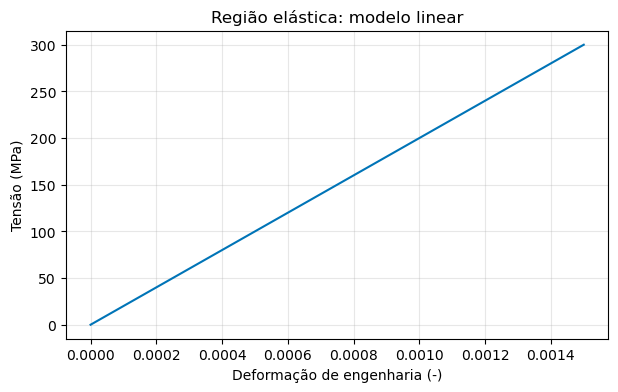

In [10]:
deformacao = np.linspace(0, 0.0015, 40)
E_MPa = 200_000.0
tensao_MPa = E_MPa * deformacao

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(deformacao, tensao_MPa, color="#0074B7")
ax.set(xlabel="Deformação de engenharia (-)", ylabel="Tensão (MPa)", title="Região elástica: modelo linear")
ax.grid(True, alpha=0.3)
plt.show()

**Interpretação:** a inclinação corresponde ao módulo elástico adotado. O modelo não descreve escoamento plástico, ruptura ou o comportamento completo de um material real.

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Gráficos de dispersão e ajuste linear</div>

**Problema — Tratamento de dados experimentais.** Um conjunto de pares $(x,y)$ pode ser representado com `scatter`, sem presumir continuidade entre medições. Para uma tendência aproximadamente linear, o NumPy pode estimar coeficientes de uma reta $y=ax+b$ por `np.polyfit`.

A reta ajustada é um modelo empírico. Sua adequação deve ser avaliada com base nos resíduos, na faixa de medição e no conhecimento físico do processo.

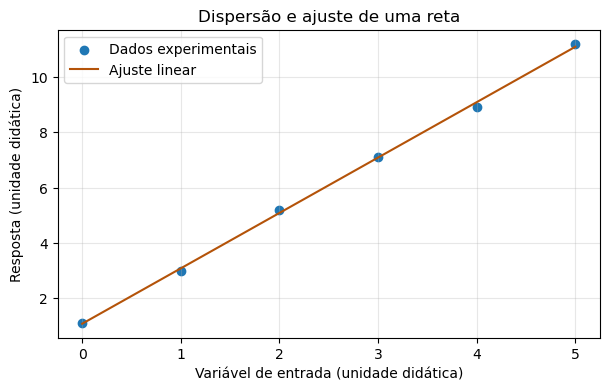

Reta estimada: y = 2.003 x + 1.076


In [11]:
x = np.array([0, 1, 2, 3, 4, 5], dtype=float)
y = np.array([1.1, 3.0, 5.2, 7.1, 8.9, 11.2])
a, b = np.polyfit(x, y, 1)
x_linha = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, y, label="Dados experimentais")
ax.plot(x_linha, a * x_linha + b, color="#b45309", label="Ajuste linear")
ax.set(xlabel="Variável de entrada (unidade didática)", ylabel="Resposta (unidade didática)", title="Dispersão e ajuste de uma reta")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
print(f"Reta estimada: y = {a:.3f} x + {b:.3f}")

**Interpretação:** a reta resume a tendência dos pontos, mas não prova causalidade. Em uma aplicação de Engenharia, as grandezas e suas unidades precisam ser identificadas antes de utilizar o ajuste.

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Múltiplos gráficos e organização visual</div>

Podemos organizar duas representações relacionadas em uma única figura usando `plt.subplots(1, 2)`. Isso é útil, por exemplo, para comparar valores medidos e seus desvios, mantendo rótulos claros. Evite colocar muitas informações no mesmo painel ou usar escalas diferentes sem indicação.

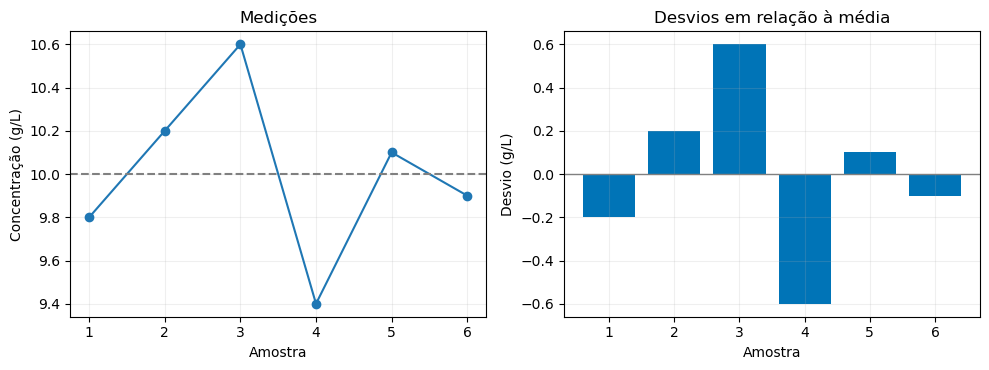

In [12]:
medidas = np.array([9.8, 10.2, 10.6, 9.4, 10.1, 9.9])
indice = np.arange(1, len(medidas) + 1)
media = np.mean(medidas)

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.8))
eixos[0].plot(indice, medidas, "o-")
eixos[0].axhline(media, linestyle="--", color="gray")
eixos[0].set(xlabel="Amostra", ylabel="Concentração (g/L)", title="Medições")
eixos[1].bar(indice, medidas - media, color="#0074B7")
eixos[1].axhline(0, color="gray", linewidth=1)
eixos[1].set(xlabel="Amostra", ylabel="Desvio (g/L)", title="Desvios em relação à média")
for eixo in eixos:
    eixo.grid(True, alpha=0.2)
fig.tight_layout()
plt.show()

**Interpretação:** o primeiro painel apresenta as medições; o segundo destaca os desvios positivos e negativos em relação à média. As escalas verticais são diferentes e estão explicitadas.

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Salvando figuras para relatórios</div>

Para incluir um gráfico em relatório ou apresentação, salve a figura com `fig.savefig()`. Arquivos PNG são adequados para visualização comum; SVG e PDF preservam elementos vetoriais em muitos casos. O argumento `dpi` controla a resolução da imagem rasterizada.

O exemplo a seguir cria uma pasta própria para as figuras geradas pelo notebook, evitando modificar a pasta `img` que contém o logotipo institucional.

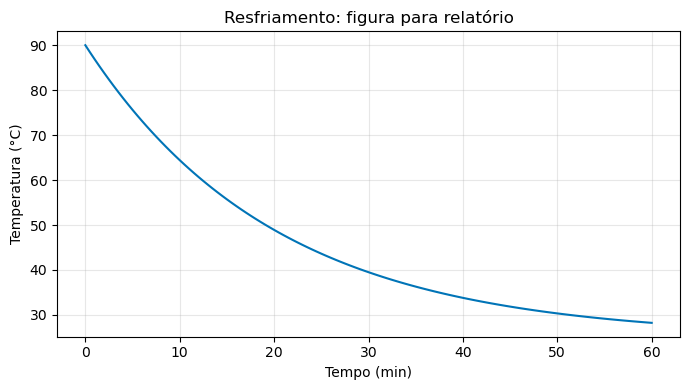

Figura salva em: C:\Users\elilt\OneDrive\AULAS_PROVAS_UESC_LATEX\SITE_AULAS_UESC_ELILTON\CET002\AULAS\figuras_notebook13\resfriamento.png


In [13]:
from pathlib import Path

pasta_figuras = Path("figuras_notebook13")
pasta_figuras.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tempo_min, T_modelo, color="#0074B7")
ax.set(xlabel="Tempo (min)", ylabel="Temperatura (°C)", title="Resfriamento: figura para relatório")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(pasta_figuras / "resfriamento.png", dpi=200, bbox_inches="tight")
plt.show()
print("Figura salva em:", (pasta_figuras / "resfriamento.png").resolve())

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Boas práticas e erros de interpretação</div>

**Boas práticas:** identificar unidades nos eixos; indicar se os dados são experimentais ou simulados; manter escalas coerentes; evitar efeitos visuais que distorçam a interpretação; incluir legenda quando necessária; verificar a correspondência entre pontos e instantes; e não extrapolar conclusões além dos dados disponíveis.

**Cuidados com a execução:** se uma figura não aparecer, verifique o ambiente e o kernel do notebook. Se uma linha parecer interrompida, investigue valores ausentes (`NaN`). Se houver grandes diferenças de escala, avalie se painéis separados são mais claros do que dois eixos verticais.

<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Exercícios de consolidação</div>

**Exercício 1 — Instrumentação.** Construa o gráfico da corrente ideal de um transmissor de 4 a 20 mA para uma faixa de 0 a 200 °C. Calcule manualmente a corrente correspondente a 100 °C.

**Exercício 2 — Controle de Qualidade.** Represente dez medições de concentração e trace dois limites de aceitação hipotéticos. Identifique os pontos fora da faixa e explique por que um gráfico não substitui a análise metrológica.

**Exercício 3 — Controle de Processos.** Construa dois gráficos: temperatura medida e referência; erro de controle em função do tempo. Utilize a definição $e=T_{SP}-T$.

**Exercício 4 — Transferência de Calor.** Compare, no mesmo gráfico, duas curvas de resfriamento com valores distintos do parâmetro $k$. Discuta qual corpo se aproxima mais rapidamente da temperatura ambiente.

**Exercício 5 — Ciências dos Materiais.** Represente dados hipotéticos de tensão e deformação de um ensaio e identifique visualmente a região aproximadamente linear. Explique por que o módulo elástico não deve ser estimado usando pontos da região plástica.

**Desafio integrador — Processos Químicos.** Simule a evolução do volume de um tanque para duas diferenças entre vazões de entrada e saída. Construa gráficos comparativos, identifique a situação de acúmulo e salve a figura em PNG.

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Síntese do notebook</div>

Neste notebook, aprendemos a transformar resultados numéricos em representações que auxiliam a interpretação física. Construímos gráficos de linhas, dispersão e barras, com aplicações em Instrumentação, Controle de Processos, Mecânica dos Fluidos, Transferência de Calor, Processos Químicos e Ciências dos Materiais.

**Ideia central:** a qualidade de um gráfico depende tanto da correção do código quanto da escolha das grandezas, das unidades e da interpretação. O Matplotlib é uma ferramenta para comunicar e investigar resultados — não um substituto para a compreensão do fenômeno de Engenharia.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Este notebook foi desenvolvido no âmbito do Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
Todos os direitos reservados © 2026
</div>